# WIA3003: Academic Project II
## QCNN Ablation and Hyperparameter Experiments

Notebook 15 changed four things at once and chose the remaining settings without testing them. This notebook tests each choice separately, so every setting of the improved QCNN has evidence behind it.

Method: start from the improved QCNN (the reference). Change one setting at a time and retrain. Every configuration is trained on the same five fitting sets and scored on the same five validation sets. These are the inner splits of the five training folds from notebook 14. **No test fold is used here**, so the test results in notebook 15 stay unbiased.

| Experiment | Settings compared | Question |
| --- | --- | --- |
| A. Ablation | Remove one of the four changes from notebook 15 | Which changes are needed? |
| B. Learning rate | 0.005, 0.01, 0.02 | Is 0.01 a suitable step size? |
| C. Batch size | 16, 32, 64 | Is 32 a suitable batch size? |
| D. Convolution layers | 1, 2, 3 | Does circuit depth help? |
| E. Random seed | 42, 123, 2026 | How much do results move with initialisation? |

Decision rule, fixed before running: keep the reference setting unless an alternative has a higher mean validation macro F1 and is better in at least four of the five folds.

The training code is in `qcnn_training.py`. Claude assisted with writing and running this notebook.

## 1.0 Load Dataset and Splits

In [1]:
import hashlib
import json
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold

folder = Path.cwd()
project_folder = folder.parent if folder.name == "notebooks" else folder
sys.path.insert(0, str(project_folder))
os.environ["PYTHONPATH"] = str(project_folder)  # worker processes import qcnn_training
from qcnn_training import REFERENCE, train

details = json.loads((project_folder / "results" / "qcnn_baseline" / "run_details.json").read_text(encoding="utf-8"))
reference_folder = project_folder / "results" / "ethnicity_evaluation"
reference_settings = json.loads((reference_folder / "cross_validation_settings.json").read_text(encoding="utf-8"))

data_path = Path.home() / "Downloads" / "Orbital, Nasal and Craniofacial Class Pattern.xls"
dataset_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
if dataset_hash != reference_settings["dataset_sha256"]:
    raise ValueError("Workbook changed since notebook 14. Verify the data first.")

df = pd.read_excel(data_path, sheet_name="Raw Data")
df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
features = details["features"]
X = df[features].apply(pd.to_numeric, errors="raise").to_numpy(dtype=float)
y = df["Gender"].astype("string").str.strip().map(details["label_mapping"]).astype(int).to_numpy()
groups = pd.DataFrame(X).groupby(list(range(len(features))), sort=False).ngroup().to_numpy()
fold_of = pd.read_csv(reference_folder / "cross_validated_predictions.csv")["fold"].to_numpy()

# Same inner split as notebook 15: first fold of a grouped split inside each training fold.
splits = []
for fold in range(5):
    train_rows = np.flatnonzero(fold_of != fold)
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
    fit_part, val_part = next(inner.split(X[train_rows], y[train_rows], groups[train_rows]))
    fit_rows, val_rows = train_rows[fit_part], train_rows[val_part]
    assert not set(groups[fit_rows]) & set(groups[val_rows])
    assert not set(fit_rows) & set(np.flatnonzero(fold_of == fold))
    splits.append((fit_rows, val_rows))
print("Fitting / validation records per split:", [(len(a), len(b)) for a, b in splits])
print("Reference settings:", REFERENCE)

Fitting / validation records per split: [(667, 166), (666, 167), (668, 166), (668, 166), (668, 166)]
Reference settings: {'scaling': 'standard', 'trainable_encoding': True, 'readout': 'sigmoid', 'layers': 2, 'learning_rate': 0.01, 'batch_size': 32, 'max_epochs': 100, 'patience': 10, 'seed': 42}


## 2.0 Configurations

Each entry changes one setting of the reference.

In [2]:
EXPERIMENTS = [
    ("Reference", "Improved QCNN (notebook 15)", {}),
    ("A. Ablation", "Min-max scaling instead of standardised", {"scaling": "minmax"}),
    ("A. Ablation", "Fixed encoding instead of trainable", {"trainable_encoding": False}),
    ("A. Ablation", "Fixed-average readout instead of learned", {"readout": "average"}),
    ("A. Ablation", "Short training (30 epochs, patience 5)", {"max_epochs": 30, "patience": 5}),
    ("B. Learning rate", "0.005", {"learning_rate": 0.005}),
    ("B. Learning rate", "0.02", {"learning_rate": 0.02}),
    ("C. Batch size", "16", {"batch_size": 16}),
    ("C. Batch size", "64", {"batch_size": 64}),
    ("D. Convolution layers", "1", {"layers": 1}),
    ("D. Convolution layers", "3", {"layers": 3}),
    ("E. Random seed", "123", {"seed": 123}),
    ("E. Random seed", "2026", {"seed": 2026}),
]

def run_job(experiment, setting, change, fold):
    fit_rows, val_rows = splits[fold]
    result, _, _, history = train({**REFERENCE, **change}, X[fit_rows], y[fit_rows], X[val_rows], y[val_rows])
    return {"Experiment": experiment, "Setting": setting, "Fold": fold, **result}, history

jobs = [(experiment, setting, change, fold)
        for experiment, setting, change in EXPERIMENTS for fold in range(5)]
print("Training runs:", len(jobs))

Training runs: 65


## 3.0 Run All Configurations

Runs train in parallel. Results are written after each run finishes.

In [3]:
output_folder = project_folder / "results" / "qcnn_ablation"
output_folder.mkdir(parents=True, exist_ok=True)
started = time.perf_counter()
rows, histories = [], []
for row, history in Parallel(n_jobs=5, return_as="generator_unordered")(delayed(run_job)(*job) for job in jobs):
    rows.append(row)
    histories += [{"Experiment": row["Experiment"], "Setting": row["Setting"], "Fold": row["Fold"],
                   "Epoch": epoch, "Validation loss": value} for epoch, value in enumerate(history, start=1)]
    pd.DataFrame(rows).to_csv(output_folder / "runs.csv", index=False)
runs = pd.DataFrame(rows).sort_values(["Experiment", "Setting", "Fold"]).reset_index(drop=True)
runs.to_csv(output_folder / "runs.csv", index=False)
pd.DataFrame(histories).to_csv(output_folder / "validation_history.csv", index=False)
print(f"Completed {len(runs)} runs in {(time.perf_counter() - started) / 60:.1f} minutes")

Completed 65 runs in 50.1 minutes


## 4.0 Results

Each row is compared with the reference on the same five validation sets. A negative difference means the alternative is worse than the reference.

In [4]:
reference_runs = runs[runs["Experiment"] == "Reference"].set_index("Fold")
order = [(experiment, setting) for experiment, setting, _ in EXPERIMENTS]
summary_rows = []
for experiment, setting in order:
    part = runs[(runs["Experiment"] == experiment) & (runs["Setting"] == setting)].set_index("Fold")
    difference = part["Validation macro F1"] - reference_runs["Validation macro F1"]
    summary_rows.append({
        "Experiment": experiment, "Setting": setting, "Parameters": int(part["Parameters"].iloc[0]),
        "Macro F1 mean": part["Validation macro F1"].mean(), "Macro F1 std": part["Validation macro F1"].std(),
        "Loss mean": part["Validation loss"].mean(),
        "Female recall": part["Female recall"].mean(), "Male recall": part["Male recall"].mean(),
        "Difference from reference": difference.mean(),
        "Folds better": int((difference > 0).sum()), "Folds worse": int((difference < 0).sum()),
        "Best epoch mean": part["Best epoch"].mean(), "Seconds mean": part["Seconds"].mean(),
    })
summary = pd.DataFrame(summary_rows)
display(summary.round(4))

,Experiment,Setting,Parameters,Macro F1 mean,Macro F1 std,Loss mean,Female recall,Male recall,Difference from reference,Folds better,Folds worse,Best epoch mean,Seconds mean
0,Reference,Improved QCNN (notebook 15),34,0.7850,0.0289,0.4533,0.7653,0.8060,0.0000,0,0,39.4,253.1634
1,A. Ablation,Min-max scaling instead of standardised,34,0.7964,0.0412,0.4532,0.7652,0.8273,0.0114,4,1,42.0,284.6798
2,A. Ablation,Fixed encoding instead of trainable,18,0.7842,0.0274,0.4604,0.7487,0.8188,-0.0008,1,3,63.8,357.6882
3,A. Ablation,Fixed-average readout instead of learned,29,0.7759,0.0413,0.5289,0.6987,0.8486,-0.0091,2,3,62.4,335.3220
4,A. Ablation,"Short training (30 epochs, patience 5)",34,0.7860,0.0332,0.4562,0.7404,0.8294,0.0010,2,2,20.6,116.3507
5,B. Learning rate,0.005,34,0.7848,0.0320,0.4548,0.7596,0.8102,-0.0003,1,4,49.2,278.0756
6,B. Learning rate,0.02,34,0.7905,0.0319,0.4544,0.7624,0.8188,0.0055,2,3,16.0,121.7280
7,C. Batch size,16,34,0.7804,0.0371,0.4561,0.7405,0.8188,-0.0046,2,3,20.4,239.5164
8,C. Batch size,64,34,0.7867,0.0397,0.4548,0.7540,0.8188,0.0017,3,2,41.6,146.2783
9,D. Convolution layers,1,28,0.7939,0.0297,0.4626,0.7597,0.8273,0.0089,4,1,41.0,136.3073


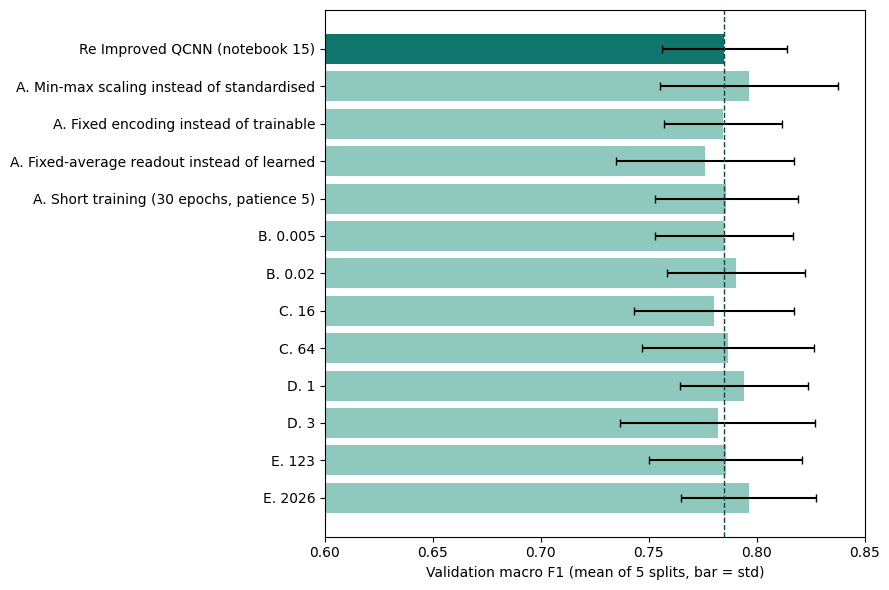

In [5]:
plot_data = summary.iloc[::-1]
colours = ["#0F766E" if experiment == "Reference" else "#8FC9BD" for experiment in plot_data["Experiment"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_data["Experiment"].str.slice(0, 2).str.strip() + " " + plot_data["Setting"],
        plot_data["Macro F1 mean"], xerr=plot_data["Macro F1 std"], color=colours, capsize=3)
ax.axvline(summary.loc[0, "Macro F1 mean"], color="#17433F", linestyle="--", linewidth=1)
ax.set_xlim(0.6, 0.85)
ax.set_xlabel("Validation macro F1 (mean of 5 splits, bar = std)")
fig.tight_layout()
fig.savefig(output_folder / "validation_macro_f1.png", dpi=200, bbox_inches="tight")
plt.show()

## 5.0 Decisions

Apply the rule stated at the top. Random seed is not a setting to choose, so it is reported as variation only.

In [6]:
reference_value = {"A. Ablation": "Keep the change from notebook 15", "B. Learning rate": "0.01",
                   "C. Batch size": "32", "D. Convolution layers": "2"}
decisions = []
for experiment, kept in reference_value.items():
    for _, row in summary[summary["Experiment"] == experiment].iterrows():
        replace = row["Difference from reference"] > 0 and row["Folds better"] >= 4
        decisions.append({
            "Experiment": experiment, "Alternative": row["Setting"],
            "Difference from reference": row["Difference from reference"],
            "Folds better": row["Folds better"], "Folds worse": row["Folds worse"],
            "Decision": "Adopt the alternative" if replace else f"Keep reference ({kept})",
        })
decisions = pd.DataFrame(decisions)
display(decisions.round(4))

seed_runs = summary[summary["Experiment"].isin(["Reference", "E. Random seed"])]
print("Macro F1 across three seeds:", seed_runs["Macro F1 mean"].round(4).tolist(),
      "range", round(seed_runs["Macro F1 mean"].max() - seed_runs["Macro F1 mean"].min(), 4))

,Experiment,Alternative,Difference from reference,Folds better,Folds worse,Decision
0,A. Ablation,Min-max scaling instead of standardised,0.0114,4,1,Adopt the alternative
1,A. Ablation,Fixed encoding instead of trainable,-0.0008,1,3,Keep reference (Keep the change from notebook 15)
2,A. Ablation,Fixed-average readout instead of learned,-0.0091,2,3,Keep reference (Keep the change from notebook 15)
3,A. Ablation,"Short training (30 epochs, patience 5)",0.0010,2,2,Keep reference (Keep the change from notebook 15)
4,B. Learning rate,0.005,-0.0003,1,4,Keep reference (0.01)
5,B. Learning rate,0.02,0.0055,2,3,Keep reference (0.01)
6,C. Batch size,16,-0.0046,2,3,Keep reference (32)
7,C. Batch size,64,0.0017,3,2,Keep reference (32)
8,D. Convolution layers,1,0.0089,4,1,Adopt the alternative
9,D. Convolution layers,3,-0.0032,2,3,Keep reference (2)


Macro F1 across three seeds: [0.785, 0.7856, 0.7963] range 0.0113


## 6.0 Save Results

In [7]:
summary.to_csv(output_folder / "summary.csv", index=False)
decisions.to_csv(output_folder / "decisions.csv", index=False)
settings = {
    "dataset_sha256": dataset_hash, "features": features, "reference": REFERENCE,
    "experiments": [{"experiment": e, "setting": s, "change": c} for e, s, c in EXPERIMENTS],
    "splits": "inner validation split of each notebook 14 training fold; test folds unused",
    "decision_rule": "adopt an alternative only if mean validation macro F1 is higher and it is better in at least 4 of 5 folds",
}
(output_folder / "settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Saved results to:", output_folder)

Saved results to: C:\Users\jwenn\Desktop\UM\FYP\FYP-Project\results\qcnn_ablation
